In [36]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix, jaccard_score

In [ ]:
df = pd.read_csv('knn_project\knn_dataset.csv')
df.dtypes

In [37]:
df = df.dropna()
df = df.reset_index(drop=True)
df.isna().sum()

Study_Hours     0
Attendance      0
Previous_GPA    0
Assignments     0
Exam_Score      0
Admitted        0
dtype: int64

In [38]:
df.columns

Index(['Study_Hours', 'Attendance', 'Previous_GPA', 'Assignments',
       'Exam_Score', 'Admitted'],
      dtype='str')

In [39]:
x = df[['Study_Hours', 'Attendance', 'Previous_GPA', 'Assignments',
       'Exam_Score']]
y = df['Admitted']

In [40]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

In [41]:
scaler = preprocessing.StandardScaler().fit(x_train)
x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

In [42]:
k = 4
neigh = KNeighborsClassifier(n_neighbors = k).fit(x_train, y_train)

In [43]:
y_hat = neigh.predict(x_test)

In [44]:
jaccard_score(y_test, y_hat, pos_label=1)

0.8222222222222222

In [45]:
print(classification_report(y_test, y_hat))

              precision    recall  f1-score   support

           0       0.79      0.79      0.79        19
           1       0.90      0.90      0.90        41

    accuracy                           0.87        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.87      0.87      0.87        60



Confusion matrix without normalization
[[37  4]
 [ 4 15]]


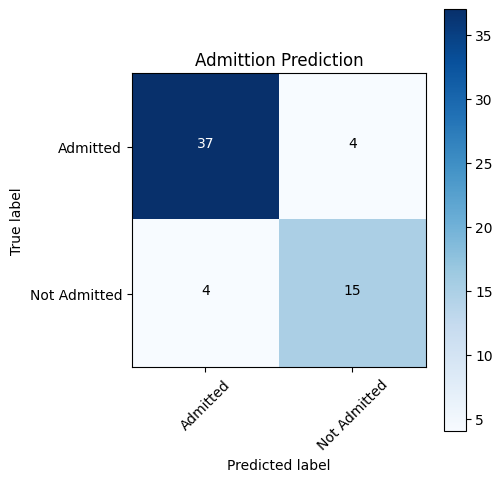

In [47]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion Matrix',
                          cmap=plt.cm.Blues):

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print("Confusion matrix without normalization")

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.

    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(
            j,
            i,
            format(cm[i, j], fmt),
            horizontalalignment='center',
            color='white' if cm[i, j] > thresh else 'black'
        )

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

cnf_matrix = confusion_matrix(y_test, y_hat, labels=[1, 0])

plt.figure(figsize=(5,5))

plot_confusion_matrix(
    cnf_matrix,
    classes=['Admitted', 'Not Admitted'],
    normalize=False,
    title='Admittion Prediction'
)

plt.show()